# Geometric Intuition of Support Vector Machines (SVM)

In this notebook, we will explore how Support Vector Machines work geometrically. We will cover:
1. **Linear SVM**: Maximizing the margin on linearly separable data.
2. **Non-linear SVM & Kernels**: Projecting non-linearly separable data into higher dimensions to find a separating hyperplane.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_circles
from sklearn.svm import SVC

# Set random seed for reproducibility
np.random.seed(42)

## Part 1: Linearly Separable Data & Maximum Margin

For linearly separable data, the goal of a Support Vector Machine is to find the **Maximum Margin Hyperplane** that separates the classes.
- The **margin** is the distance between the decision boundary (hyperplane) and the closest data points of any class.
- These closest data points are called **support vectors** because they "support" or define the position and orientation of the boundary.

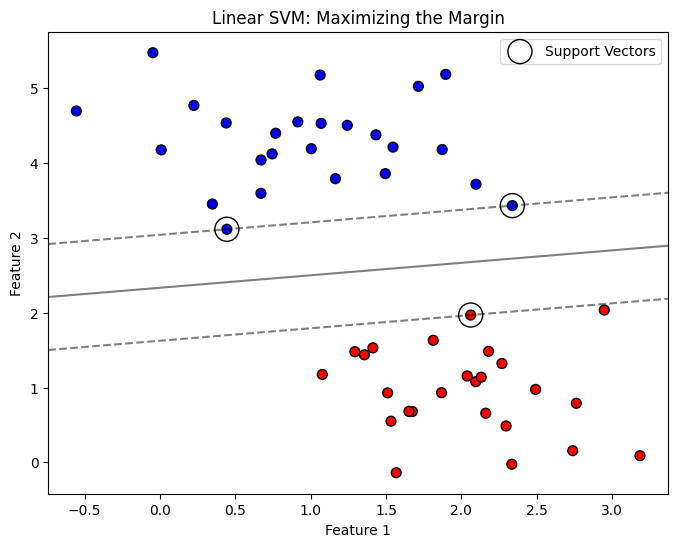

In [2]:
# Generate linearly separable data
X_linear, y_linear = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)

# Fit a Linear SVM
model_linear = SVC(kernel='linear', C=1E10)
model_linear.fit(X_linear, y_linear)

# Helper function to plot SVM decision boundaries and margins
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Create grid to evaluate model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Plot decision boundary and margins
    ax.contour(X, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    # Highlight support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=300, linewidth=1, facecolors='none', edgecolors='black', label='Support Vectors')

# Visualize
plt.figure(figsize=(8, 6))
plt.scatter(X_linear[:, 0], X_linear[:, 1], c=y_linear, s=50, cmap='bwr', edgecolors='k')
plot_svc_decision_function(model_linear)
plt.title("Linear SVM: Maximizing the Margin")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

## Part 2: Non-Linearly Separable Data & The Kernel Trick

When data cannot be separated by a straight line, we can project the data into a **higher-dimensional space** where a linear boundary *can* separate them. This process is made computationally efficient using the **Kernel Trick**, which calculates relationships between points in higher dimensions without explicitly transforming them.

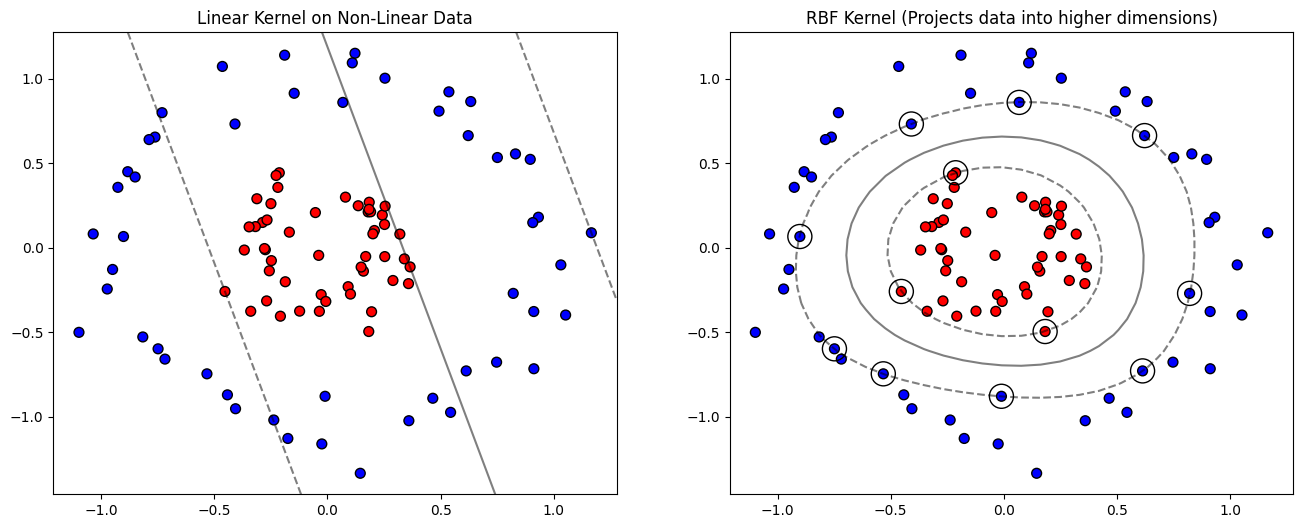

In [3]:
# Generate concentric (non-linear) data
X_circle, y_circle = make_circles(n_samples=100, factor=0.3, noise=0.1, random_state=0)

# Fit a Linear SVM (which will fail)
model_fail = SVC(kernel='linear').fit(X_circle, y_circle)

# Fit an RBF (Radial Basis Function) Kernel SVM
model_rbf = SVC(kernel='rbf', C=1E6).fit(X_circle, y_circle)

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: Linear kernel failure
axes[0].scatter(X_circle[:, 0], X_circle[:, 1], c=y_circle, s=50, cmap='bwr', edgecolors='k')
plot_svc_decision_function(model_fail, ax=axes[0], plot_support=False)
axes[0].set_title("Linear Kernel on Non-Linear Data")

# Right plot: RBF Kernel success
axes[1].scatter(X_circle[:, 0], X_circle[:, 1], c=y_circle, s=50, cmap='bwr', edgecolors='k')
plot_svc_decision_function(model_rbf, ax=axes[1], plot_support=True)
axes[1].set_title("RBF Kernel (Projects data into higher dimensions)")

plt.show()

## Part 3: Visualizing the 3D Projection

To see how the Kernel works geometrically, let's explicitly calculate and visualize a simple 3D transformation:

$$z = e^{-(x^2 + y^2)}$$

This maps our 2D coordinates into a 3D landscape where a flat horizontal plane easily cuts through and separates the two classes.

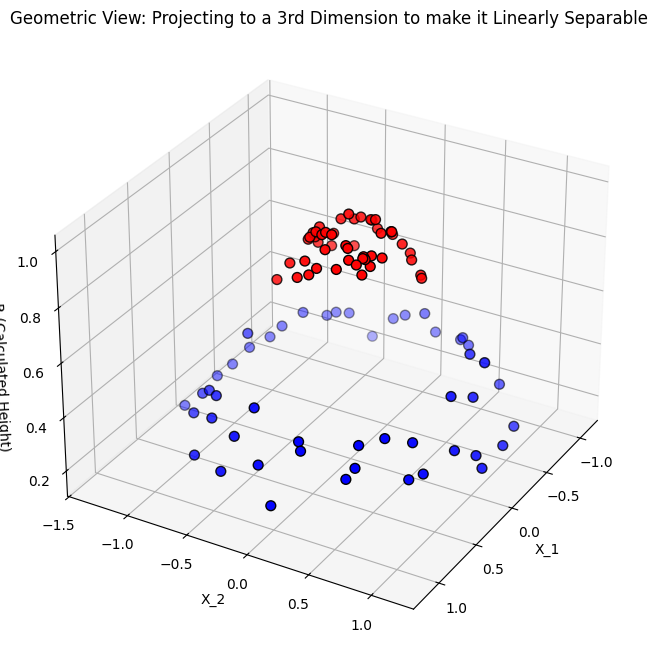

In [4]:
from mpl_toolkits import mplot3d

# Compute a radial basis function manually for 3D visualization
r = np.exp(-(X_circle ** 2).sum(1))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

# Plot the 3D representation
ax.scatter3D(X_circle[:, 0], X_circle[:, 1], r, c=y_circle, s=50, cmap='bwr', edgecolors='k')
ax.set_xlabel('X_1')
ax.set_ylabel('X_2')
ax.set_zlabel('R (Calculated Height)')
ax.set_title('Geometric View: Projecting to a 3rd Dimension to make it Linearly Separable')

# Adjust viewing angle
ax.view_init(elev=30, azim=30)
plt.show()